# 01 Dataset audit
Inspect raw folders before writing `configs/data.yaml` and `manifests.py`.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import Audio, display
from audio_df.helpers.research.audit import audio_stats, check_audio, e4_noise_bank, read_key, tree

RAW, SR = Path("../data/raw"), 16000

d:\MyCode\projects\GC2-EchoJEV\SystemCode\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Overview
Audio files and disk size counted from the folders; notes from `configs/data.yaml`.

In [2]:
import os
import yaml

cfg = yaml.safe_load(open("../configs/data.yaml"))
DATASETS = {  # name: (data.yaml block, audio folder inside its root)
    "ASVspoof 2019 LA": ("dataset", ""),
    "ASVspoof 2021 LA": ("asvspoof2021", cfg["asvspoof2021"]["audio_dir"]),
    "ASVspoof 2021 DF": ("asvspoof2021df", "flac"),
    "In-the-Wild": ("in_the_wild", ""),
    "MUSAN noise": ("musan", ""),
}

rows = []
for name, (block, sub) in DATASETS.items():
    folder = Path("..") / cfg[block]["root"] / sub
    n, gb = audio_stats(folder) if folder.exists() else (0, 0.0)
    rows.append({"dataset": name, "folder": folder.as_posix()[3:], "audio files": f"{n:,}",
                 "size GB": round(gb, 1), "notes": cfg[block]["notes"]})
pd.set_option("display.max_colwidth", None)
pd.DataFrame(rows).style.hide(axis="index").set_properties(subset=["notes"], **{"text-align": "left", "white-space": "normal"})


dataset,folder,audio files,size GB,notes
ASVspoof 2019 LA,data/raw/ASVspoof2019/LA,"122,299",7.600000,"Training corpus. train 25,380 / dev 24,844 / eval 71,237. Attacks A01-A06 in train/dev, A07-A19 only in eval (unseen). About 1 bona fide per 9 spoof. Leading silence leaks the label, so all splits are trimmed. The folders also hold 838 speaker-verification enrollment clips (LA_D_A*, LA_E_A*) that are not in the CM protocol and are never used."
ASVspoof 2021 LA,data/raw/ASVspoof2021/ASVspoof2021_LA_eval/flac_ffmpeg,"181,566",8.800000,"Test only. 2019-style attacks (A07-A19) sent over 7 telephony channels. Key phases: eval 148,176 (official) / progress 16,464 / hidden 16,926 (silence removed by organisers). 18,452 bona fide / 163,114 spoof. Scored raw, from the re-encoded flac_ffmpeg copy."
ASVspoof 2021 DF,data/raw/ASVspoof2021/ASVspoof2021_DF_eval/flac,"611,829",34.400000,"Test only, Hugging Face mirror. Compressed media codecs and extra vocoders. Subsets: eval 533,928 (official) / progress 59,325 / hidden 18,576. 22,617 bona fide / 589,212 spoof. Scored raw."
In-the-Wild,data/raw/InTheWild,"31,779",8.700000,"Test only. 19,963 bona fide / 11,816 spoof, public-figure speech from the web; 54 speakers in meta.csv (the paper says 58). Scored raw."
MUSAN noise,data/raw/musan/noise,930,0.700000,"Not a spoof dataset. Noise clips mixed into a fixed 10k subset of 2019 eval at 10 dB SNR to make eval_noise_10db (MP3, Opus and 8 kHz copies of the same subset need no extra data)."


## ASVspoof 2019 LA

In [3]:
tree(RAW / "ASVspoof2019/LA")

ASVspoof2019_LA_asv_protocols/ {'.txt': 10}
ASVspoof2019_LA_asv_scores/ {'.txt': 2}
ASVspoof2019_LA_cm_protocols/ {'.txt': 3}
ASVspoof2019_LA_dev/ {'.txt': 1}
  flac/ {'.flac': 24986}
ASVspoof2019_LA_eval/ {'.txt': 1}
  flac/ {'.flac': 71933}
ASVspoof2019_LA_train/ {'.txt': 1}
  flac/ {'.flac': 25380}


In [4]:
k19 = read_key(RAW / "ASVspoof2019/LA/ASVspoof2019_LA_cm_protocols/ASVspoof2019.LA.cm.train.trn.txt")
k19.head()

0 {'LA_0082': 1308, 'LA_0083': 1308, 'LA_0089': 1308, 'LA_0092': 1308, 'LA_0093': 1308, 'LA_0094': 1308, 'LA_0095': 1308, 'LA_0096': 1308, 'LA_0079': 1243, 'LA_0080': 1243, 'LA_0081': 1243, 'LA_0084': 1243, 'LA_0085': 1243, 'LA_0086': 1243, 'LA_0087': 1243, 'LA_0088': 1243, 'LA_0090': 1243, 'LA_0091': 1243, 'LA_0097': 1243, 'LA_0098': 1243}
2 {'-': 25380}
3 {'A01': 3800, 'A02': 3800, 'A03': 3800, 'A04': 3800, 'A05': 3800, 'A06': 3800, '-': 2580}
4 {'spoof': 22800, 'bonafide': 2580}


,0,1,2,3,4
0,LA_0079,LA_T_1138215,-,-,bonafide
1,LA_0079,LA_T_1271820,-,-,bonafide
2,LA_0079,LA_T_1272637,-,-,bonafide
3,LA_0079,LA_T_1276960,-,-,bonafide
4,LA_0079,LA_T_1341447,-,-,bonafide


In [5]:
p19 = check_audio(k19[1], RAW / "ASVspoof2019/LA/ASVspoof2019_LA_train/flac")

clips: 25380 | missing audio: 0


,sample_rate,duration_s,format
count,200.0,200.000000,200
unique,NaN,NaN,1
top,NaN,NaN,FLAC
freq,NaN,NaN,200
mean,16000.0,3.459520,NaN
std,0.0,1.359012,NaN
min,16000.0,0.948375,NaN
25%,16000.0,2.475078,NaN
50%,16000.0,3.233562,NaN
75%,16000.0,4.147484,NaN


## ASVspoof 2021 LA eval

In [6]:
tree(RAW / "ASVspoof2021")

ASVspoof2021_DF_eval/ {'.unpacked': 1, '.csv': 1}
  flac/ {'.flac': 611829}
ASVspoof2021_LA_eval/ {'.txt': 3}
  flac/ {'.flac': 181566}
  flac_ffmpeg/ {'.flac': 181566}
keys/ {}
  LA/ {'.npy': 3, '.txt': 1}


In [7]:
trl = read_key(RAW / "ASVspoof2021/ASVspoof2021_LA_eval/ASVspoof2021.LA.cm.eval.trl.txt")
trl.head()  # ids only, no labels

,0
0,LA_E_9332881
1,LA_E_6866159
2,LA_E_5464494
3,LA_E_4759417
4,LA_E_2667748


In [8]:
k21 = read_key(RAW / "ASVspoof2021/keys/LA/CM/trial_metadata.txt")
k21.head()

2 {'alaw': 25938, 'ulaw': 25938, 'gsm': 25938, 'pstn': 25938, 'g722': 25938, 'opus': 25938, 'none': 25938}
3 {'loc_tx': 75110, 'ita_tx': 27290, 'sin_tx': 27290, 'mad_tx': 25938, '-': 25938}
4 {'bonafide': 18452, 'A16': 12740, 'A13': 12663, 'A10': 12649, 'A11': 12572, 'A08': 12565, 'A14': 12558, 'A07': 12544, 'A17': 12516, 'A19': 12516, 'A12': 12488, 'A15': 12467, 'A09': 12432, 'A18': 12404}
5 {'spoof': 163114, 'bonafide': 18452}
6 {'notrim': 164640, 'only_speech': 16926}
7 {'eval': 148176, 'hidden': 16926, 'progress': 16464}


,0,1,2,3,4,5,6,7
0,LA_0009,LA_E_9332881,alaw,ita_tx,A07,spoof,notrim,eval
1,LA_0009,LA_E_6866159,alaw,ita_tx,A07,spoof,notrim,eval
2,LA_0009,LA_E_5464494,alaw,sin_tx,A07,spoof,notrim,eval
3,LA_0009,LA_E_4759417,alaw,sin_tx,A07,spoof,notrim,eval
4,LA_0009,LA_E_2667748,alaw,loc_tx,A07,spoof,notrim,eval


In [9]:
p21 = check_audio(k21[1], RAW / "ASVspoof2021/ASVspoof2021_LA_eval/flac")

clips: 181566 | missing audio: 0


,sample_rate,duration_s,format
count,200.0,200.000000,200
unique,NaN,NaN,1
top,NaN,NaN,FLAC
freq,NaN,NaN,200
mean,16000.0,2.578178,NaN
std,0.0,1.176805,NaN
min,16000.0,0.672438,NaN
25%,16000.0,1.737250,NaN
50%,16000.0,2.323781,NaN
75%,16000.0,3.142500,NaN


## In-the-Wild

In [10]:
tree(RAW / "InTheWild", depth=1)

release_in_the_wild/ {'.wav': 31779, '.txt': 1, '.csv': 1}


In [11]:
itw = pd.read_csv(RAW / "InTheWild/release_in_the_wild/meta.csv")
print(itw.label.value_counts().to_dict(), "| speakers:", itw.speaker.nunique())
itw.head()

{'bona-fide': 19963, 'spoof': 11816} | speakers: 54


,file,speaker,label
0,0.wav,Alec Guinness,spoof
1,1.wav,Alec Guinness,spoof
2,2.wav,Barack Obama,spoof
3,3.wav,Alec Guinness,spoof
4,4.wav,Christopher Hitchens,bona-fide


In [12]:
pitw = check_audio(itw.file, RAW / "InTheWild/release_in_the_wild", ext="")

clips: 31779 | missing audio: 0


,sample_rate,duration_s,format
count,200.0,200.000000,200
unique,NaN,NaN,1
top,NaN,NaN,WAV
freq,NaN,NaN,200
mean,16000.0,3.898052,NaN
std,0.0,2.738629,NaN
min,16000.0,0.743000,NaN
25%,16000.0,2.107766,NaN
50%,16000.0,3.147031,NaN
75%,16000.0,4.839266,NaN


asvspoof2021df
> **One-off shortcut (2026-10-25):** A1, A4, A3 and FP1 were evaluated on DF using **10,000-clip stratified samples** of `asvspoof2021df_eval` and `asvspoof2021df_hidden` (label × attack × codec, seed 1337; class balance and all 9 codecs kept), saved as `data/manifests_full/*_10k.csv` (gitignored). A2, D1, D2 and D3 are evaluated on the **full** manifests (533,928 and 18,576 clips), which are back in `data/manifests/`.

## Trim check

In [13]:
from audio_df.data.manifests import load_manifest
from audio_df.helpers.audio import load_audio
from audio_df.helpers.eval_audio import trim_silence

df = load_manifest("../data/manifests/dev.csv", "..")
row = df[df.label == "bonafide"].sample(1, random_state=0).iloc[0]
x = load_audio(row.path, SR)
xt = trim_silence(x)
print(row.utt_id, f"raw {len(x)/SR:.2f}s -> trimmed {len(xt)/SR:.2f}s")

LA_D_6124905 raw 4.48s -> trimmed 2.75s


In [14]:
display(Audio(x, rate=SR))

In [15]:
display(Audio(xt, rate=SR))

## Degraded audio (E4)
The robustness test sets degrade the 2019 LA eval clips with the four conditions in
`configs/e4_degradations.yaml`:
- **eval_mp3_32k:** MP3 at 32 kbps.
- **eval_opus_16k:** Opus at 16 kbps.
- **eval_noise_10db:** a MUSAN noise file mixed in at 10 dB signal-to-noise ratio (SNR).
- **eval_resample_8k:** down to 8 kHz and back to 16 kHz, which removes everything above 4 kHz.

Order matters. The degradation is applied to the raw clip, and trimming happens afterwards, when the model is
evaluated. So below, each version is degraded first and then trimmed, the same as the models saw it. The clip is
the bona fide one from the trim check above. Noise is drawn from `data/raw/musan/noise` with the same per-clip
choice as `scripts/make_degraded.py`, and that condition is skipped when MUSAN is not downloaded.

In [3]:
import librosa
import matplotlib.pyplot as plt
import numpy as np
import yaml
from audio_df.data.degrade import degrade

E4 = yaml.safe_load(open("../configs/e4_degradations.yaml"))
noise_dir = Path("..") / E4["conditions"]["eval_noise_10db"]["noise_dir"]

versions = {"clean": xt}
for name, spec in E4["conditions"].items():
    bank = e4_noise_bank(E4, "..", row.utt_id, name) if spec["type"] == "noise" else None
    if spec["type"] == "noise" and bank is None:
        print(f"{name}: skipped, no MUSAN noise in {noise_dir.resolve()}")
        continue
    versions[name] = trim_silence(degrade(x, SR, name, E4, E4["seed"], row.utt_id, noise_bank=bank))
pd.Series({k: round(len(v) / SR, 2) for k, v in versions.items()}, name="seconds after trimming")

eval_noise_10db: skipped, no MUSAN noise in /Users/zuttome/LocalDocs/Learning/College/NUS/MTech-AIS/PS/GC2/SystemCode/data/raw/musan/noise


clean               2.75
eval_mp3_32k        2.75
eval_opus_16k       2.75
eval_resample_8k    2.75
Name: seconds after trimming, dtype: float64

### Spectrograms
Same clip, each version after trimming. The 8 kHz round trip leaves nothing above 4 kHz; the codecs thin out
the high band.

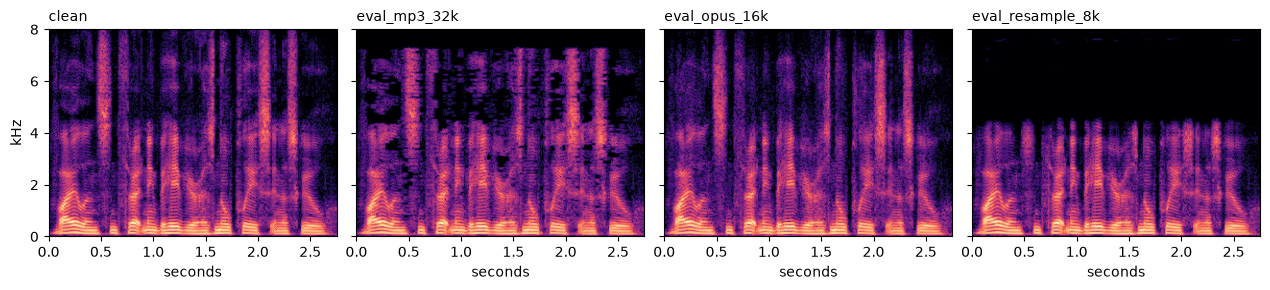

In [4]:
fig, axes = plt.subplots(1, len(versions), figsize=(3.2 * len(versions), 3), sharey=True)
for ax, (name, y) in zip(np.atleast_1d(axes), versions.items()):
    S = librosa.amplitude_to_db(np.abs(librosa.stft(y, n_fft=512, hop_length=160)), ref=np.max)
    ax.imshow(S, origin="lower", aspect="auto", cmap="magma", vmin=-80, vmax=0,
              extent=[0, len(y) / SR, 0, SR / 2000])
    ax.set_title(name, loc="left", fontsize=10)
    ax.set_xlabel("seconds")
np.atleast_1d(axes)[0].set_ylabel("kHz")
plt.tight_layout()
plt.show()

### Listen

In [5]:
for name, y in versions.items():
    print(name)
    display(Audio(y, rate=SR))

clean


eval_mp3_32k


eval_opus_16k


eval_resample_8k
